# 02 · Model selection

**Protocol** (identical for every candidate):
* Corrected data, all 5,677 players. No outlier deletion.
* Target: `log(value)`. Pricing is multiplicative: missing a €100M player by €1M is fine, missing a €200k player by €1M is a 6× miss.
* 5-fold CV with the same folds for every model. Scaling, tuning (`RidgeCV`, `LassoCV`) and encoding happen inside the folds. Every score is out-of-fold.

**Metrics**
* `median_ape`: median absolute % error in euros. *"For a typical player, how far off is the price?"* This is the headline metric.
* `within_25`: share of players priced within ±25%.
* `rmse_log`, `r2_log`: on the fitting scale.
* `r2_eur`: R² in euros. It is dominated by ~25 superstars, so it is shown only for reference.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer, StandardScaler

warnings.filterwarnings("ignore")
d = pd.read_csv("../data/player_stats_clean.csv")
SKILLS = [c for c in d.columns[6:] if c not in ("value", "value_m", "log_value", "is_gk")]
FEATS = SKILLS + ["height", "weight", "age", "is_gk"]
X, y = d[FEATS], d["log_value"]
CV = KFold(5, shuffle=True, random_state=42)


def metrics(y_log, p_log):
    y_log, p_log = np.asarray(y_log), np.asarray(p_log)
    ape = np.abs(np.exp(p_log - y_log) - 1)
    ye, pe = np.exp(y_log), np.exp(p_log)
    return {
        "median_ape": np.median(ape),
        "within_25": np.mean(ape < 0.25),
        "rmse_log": np.sqrt(np.mean((p_log - y_log) ** 2)),
        "r2_log": 1 - np.sum((p_log - y_log) ** 2) / np.sum((y_log - y_log.mean()) ** 2),
        "r2_eur": 1 - np.sum((pe - ye) ** 2) / np.sum((ye - ye.mean()) ** 2),
    }


def show(tab):
    return tab.style.format({"median_ape": "{:.1%}", "within_25": "{:.1%}", "rmse_log": "{:.3f}",
                             "r2_log": "{:.3f}", "r2_eur": "{:.3f}"})


print(len(FEATS), "features:", FEATS)

37 features: ['ball_control', 'dribbling', 'slide_tackle', 'stand_tackle', 'aggression', 'reactions', 'att_position', 'interceptions', 'vision', 'composure', 'crossing', 'short_pass', 'long_pass', 'acceleration', 'stamina', 'strength', 'balance', 'sprint_speed', 'agility', 'jumping', 'heading', 'shot_power', 'finishing', 'long_shots', 'curve', 'fk_acc', 'penalties', 'volleys', 'gk_positioning', 'gk_diving', 'gk_handling', 'gk_kicking', 'gk_reflexes', 'height', 'weight', 'age', 'is_gk']


## Candidates
Linear models get a spline on age, because value peaks mid-career (see 04). The "degree-2" Ridge adds every pairwise interaction (~700 terms) with CV-tuned shrinkage.

In [2]:
age_spline = make_column_transformer((SplineTransformer(n_knots=6), ["age"]), remainder=StandardScaler())
HGB_PARAMS = dict(max_iter=1500, learning_rate=0.03, max_leaf_nodes=31, min_samples_leaf=10,
                  l2_regularization=1.0, random_state=0)
models = {
    "Median (baseline)": DummyRegressor(strategy="median"),
    "OLS": LinearRegression(),
    "OLS + age spline": make_pipeline(age_spline, LinearRegression()),
    "RidgeCV + age spline": make_pipeline(age_spline, RidgeCV(alphas=np.logspace(-3, 3, 25))),
    "LassoCV + age spline": make_pipeline(age_spline, LassoCV(cv=5, random_state=0, n_jobs=-1)),
    "Ridge, degree-2 interactions": make_pipeline(StandardScaler(), PolynomialFeatures(2), StandardScaler(),
                                                  RidgeCV(alphas=np.logspace(-1, 4, 25))),
    "Random Forest": RandomForestRegressor(n_estimators=500, min_samples_leaf=2, n_jobs=-1, random_state=0),
    "HistGradientBoosting": HistGradientBoostingRegressor(**HGB_PARAMS),
}
oof = {name: cross_val_predict(m, X, y, cv=CV) for name, m in models.items()}

# Same booster, trained on raw euros instead of log value
p_raw = cross_val_predict(HistGradientBoostingRegressor(**HGB_PARAMS), X, d["value"], cv=CV)
oof["HistGradientBoosting (raw € target)"] = np.log(np.clip(p_raw, 1e3, None))

## Blend: fixing the superstar ceiling
Trees cannot predict above the highest leaf value they saw, so boosting systematically under-prices the very best players. The interaction Ridge can extrapolate. An equal-weight average of the two out-of-fold predictions gives the following (no extra fitting, so no leakage):

In [3]:
oof["Blend: HGB + degree-2 Ridge"] = (oof["HistGradientBoosting"] + oof["Ridge, degree-2 interactions"]) / 2
table = pd.DataFrame({k: metrics(y, p) for k, p in oof.items()}).T.sort_values("median_ape")
show(table)

,median_ape,within_25,rmse_log,r2_log,r2_eur
Blend: HGB + degree-2 Ridge,12.1%,81.3%,0.212,0.975,0.926
HistGradientBoosting,12.6%,79.6%,0.229,0.971,0.893
HistGradientBoosting (raw € target),14.6%,72.5%,0.479,0.871,0.868
"Ridge, degree-2 interactions",15.1%,72.4%,0.258,0.963,0.575
Random Forest,16.9%,67.9%,0.316,0.944,0.817
RidgeCV + age spline,30.9%,41.3%,0.505,0.857,0.575
OLS + age spline,31.0%,41.3%,0.506,0.857,0.576
LassoCV + age spline,31.0%,41.3%,0.505,0.857,0.572
OLS,32.4%,39.8%,0.567,0.820,0.583
Median (baseline),64.8%,20.0%,1.336,-0.002,-0.056


### Where does each model fail? Error by value band

value_m,<250k,250–500k,0.5–1M,1–2M,2–5M,5–15M,15–30M,≥30M
n players,1127,884,1498,1100,566,293,146,63


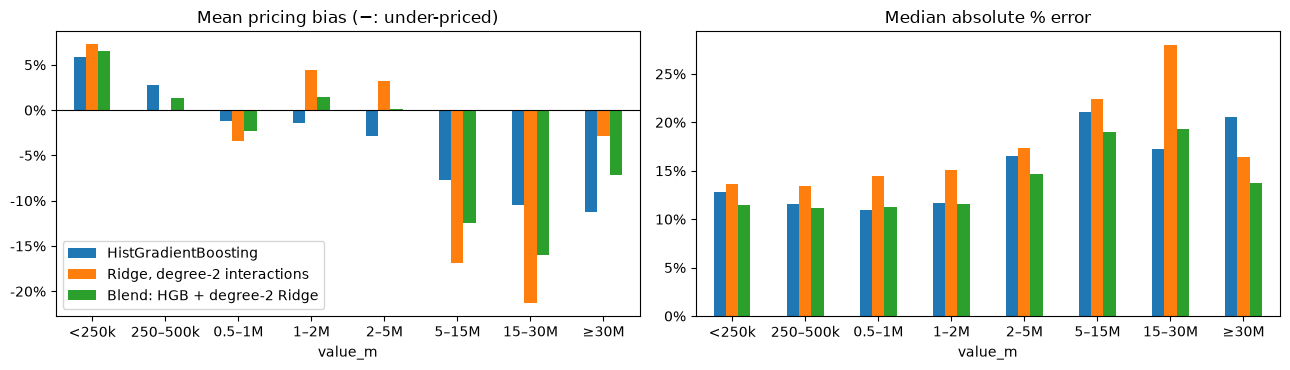

In [4]:
band = pd.cut(d.value_m, [0, 0.25, 0.5, 1, 2, 5, 15, 30, 200],
              labels=["<250k", "250–500k", "0.5–1M", "1–2M", "2–5M", "5–15M", "15–30M", "≥30M"])
bias = pd.DataFrame({k: pd.Series(oof[k] - y).groupby(band).mean()
                     for k in ["HistGradientBoosting", "Ridge, degree-2 interactions", "Blend: HGB + degree-2 Ridge"]})
apeb = pd.DataFrame({k: pd.Series(np.abs(np.exp(oof[k] - y) - 1)).groupby(band).median()
                     for k in bias.columns})
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
(np.exp(bias) - 1).plot.bar(ax=ax[0], title="Mean pricing bias (−: under-priced)", rot=0)
ax[0].axhline(0, color="k", lw=0.8)
ax[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
apeb.plot.bar(ax=ax[1], title="Median absolute % error", rot=0, legend=False)
ax[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()
display(band.value_counts().sort_index().to_frame("n players").T)

### Is the gap real? Per-fold scores

In [5]:
fold = np.zeros(len(y), int)
for i, (_, te) in enumerate(CV.split(X)):
    fold[te] = i
per_fold = pd.DataFrame({k: [metrics(y[fold == f], oof[k][fold == f])["median_ape"] for f in range(5)]
                         for k in ["Blend: HGB + degree-2 Ridge", "HistGradientBoosting", "Ridge, degree-2 interactions",
                                   "Random Forest", "OLS + age spline"]})
per_fold.style.format("{:.1%}")

,Blend: HGB + degree-2 Ridge,HistGradientBoosting,"Ridge, degree-2 interactions",Random Forest,OLS + age spline
0,12.3%,12.6%,15.3%,16.2%,29.7%
1,12.1%,12.2%,15.3%,17.4%,31.2%
2,11.7%,12.2%,14.4%,16.4%,29.9%
3,12.0%,12.9%,14.7%,16.5%,32.3%
4,12.7%,13.1%,15.9%,18.4%,32.1%


## Verdict

* **Winner: the blend of HistGradientBoosting and degree-2 Ridge.** About 12% median error, ~81% of players within ±25%, and the smallest error on the €30M+ tier. It wins in every fold.
* **Known weakness:** every model, the blend included, under-prices the €5–30M tier by ~10–15% on average, because predictions are pulled toward the mean on the log scale. The blend cuts the boosting model's bias at the very top (≥ €30M) by about a third but is not bias-free. Notebook 06 puts honest intervals around this.
* With correctly parsed values and a log target, plain OLS already reaches R² ~0.82 on log value.
* A Ridge with pairwise interactions nearly matches boosting. **Most of the non-linearity is two-way interactions**, mainly ability × age.
* Training on raw euros is clearly worse for typical players: euro-squared error lets ~25 superstars dominate the fit.

In [6]:
pd.DataFrame({"oof_hgb": oof["HistGradientBoosting"], "oof_ridge2": oof["Ridge, degree-2 interactions"],
              "oof_blend": oof["Blend: HGB + degree-2 Ridge"]}).to_csv("../data/oof_predictions.csv", index=False)
table.to_csv("../data/model_selection.csv")